# Chapter 3: NumPy and basic linear algebra

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alilouati/programming-for-data-science/blob/main/03_numpy/lecture.ipynb)

**NumPy** (Numerical Python) is the foundation of the Python data science stack: pandas, scikit-learn and most plotting libraries are built on it.

It provides

- `ndarray`, a fast multi-dimensional array of a single data type
- vectorised maths on whole arrays, without writing loops
- linear algebra, random numbers and much more

**Contents**

1. Why arrays? Lists of lists vs `ndarray`
2. Creating arrays and data types
3. Vectorised operations and speed
4. Indexing, slicing, views and boolean masks
5. Broadcasting
6. Reshaping and transposing
7. Aggregations along axes
8. Linear algebra
9. Application: a friendship graph as an adjacency matrix
10. Random numbers the modern way

In [1]:
import numpy as np
np.__version__

'2.5.5'

## 1. Lists of lists vs `ndarray`

Grades of 10 students on 3 exams (midterm 1, midterm 2, final):

In [2]:
grades = [[79, 95, 60],
          [95, 60, 61],
          [99, 67, 84],
          [76, 76, 97],
          [91, 84, 98],
          [70, 69, 96],
          [88, 65, 76],
          [67, 73, 80],
          [82, 89, 61],
          [94, 67, 88]]

# With plain lists, getting a column needs a loop or comprehension:
midterm1 = [row[0] for row in grades]
mean_per_exam = [sum(col) / len(grades) for col in zip(*grades)]
midterm1, mean_per_exam

([79, 95, 99, 76, 91, 70, 88, 67, 82, 94], [84.1, 74.5, 80.1])

With NumPy the same questions become one short expression each:

In [3]:
g = np.array(grades)
print(g[0, 2])          # final exam of student 0
print(g[2])             # all grades of student 2
print(g[:, 0])          # midterm 1 of every student
print(g[:3, :2])        # midterms of the first three students
print(g.mean(axis=0))   # mean of each exam

60
[99 67 84]
[79 95 99 76 91 70 88 67 82 94]
[[79 95]
 [95 60]
 [99 67]]
[84.1 74.5 80.1]


Every array has a `shape`, a number of dimensions `ndim` and a single `dtype`:

In [4]:
type(g), g.ndim, g.shape, g.dtype

(numpy.ndarray, 2, (10, 3), dtype('int64'))

## 2. Creating arrays and data types

In [5]:
print(np.zeros((2, 3)))
print(np.ones((2, 3), dtype=int))
print(np.eye(3))
print(np.arange(0, 10, 2))          # like range, but returns an array
print(np.linspace(0, 1, 5))         # 5 evenly spaced numbers from 0 to 1
print(np.full((2, 2), 7))

[[0. 0. 0.]
 [0. 0. 0.]]
[[1 1 1]
 [1 1 1]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[7 7]
 [7 7]]


Common dtypes: `int64`, `float64`, `bool`, `str` (shown as `<U...`) and `object`. Convert with `astype`:

In [6]:
num_strings = np.array(["1.0", "2.05", "3"])
print(num_strings.dtype)
nums = num_strings.astype(float)
print(nums, nums.dtype)
print(g.astype(np.float32).dtype)

<U4
[1.   2.05 3.  ] float64
float32


## 3. Vectorised operations and speed

Arithmetic between an array and a scalar, or between arrays of the same shape, is applied **element by element**:

In [7]:
arr = np.array([[0, 1, 2], [3, 4, 5]])
print(arr * 2)
print(arr ** 2)
print(arr + arr)
print(arr / (arr + 1))
print(np.sqrt(arr))      # "universal functions" (ufuncs) also work element-wise

[[ 0  2  4]
 [ 6  8 10]]
[[ 0  1  4]
 [ 9 16 25]]
[[ 0  2  4]
 [ 6  8 10]]
[[0.         0.5        0.66666667]
 [0.75       0.8        0.83333333]]
[[0.         1.         1.41421356]
 [1.73205081 2.         2.23606798]]


Vectorised code is not only shorter; it runs in compiled C code and is typically **tens to hundreds of times faster** than a Python loop.

In [8]:
rng = np.random.default_rng(0)
a = rng.random(1_000_000)
lst = a.tolist()

%timeit sum(x * x for x in lst)
%timeit (a * a).sum()

27.9 ms ± 847 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


1.21 ms ± 58.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## 4. Indexing, slicing, views and boolean masks

In [9]:
print(g[1:3])               # rows 1 and 2
print(g[:, 2])              # final exam column
print(g[:2, [0, 2]])        # first two students, midterm 1 and final
print(g[[0, 2]])            # rows 0 and 2 (fancy indexing)
print(g[np.ix_([0, 2], [0, 2])])   # rows 0,2 x columns 0,2

[[95 60 61]
 [99 67 84]]
[60 61 84 97 98 96 76 80 61 88]
[[79 60]
 [95 61]]
[[79 95 60]
 [99 67 84]]
[[79 60]
 [99 84]]


**Slices are views**, not copies: changing a slice changes the original array. Use `.copy()` when you need an independent array.

In [10]:
h = g.copy()
first_row = h[0]
first_row[:] = 100
print(h[:2])
print(g[:2])     # g is untouched because h was a copy

[[100 100 100]
 [ 95  60  61]]
[[79 95 60]
 [95 60 61]]


**Boolean masks** select elements that satisfy a condition. This is the heart of data filtering, and pandas works the same way.

In [11]:
female = np.array([True, False, True, True, False, True, False, False, False, False])
print(g[female])                       # rows of female students
print(g[g[:, 2] < 70])                 # students with a final below 70
print((g >= 90).sum(axis=0))           # how many 90+ grades per exam

capped = g.copy()
capped[capped < 70] = 70               # raise every grade below 70 to 70
capped

[[79 95 60]
 [99 67 84]
 [76 76 97]
 [70 69 96]]
[[79 95 60]
 [95 60 61]
 [82 89 61]]
[4 1 3]


array([[79, 95, 70],
       [95, 70, 70],
       [99, 70, 84],
       [76, 76, 97],
       [91, 84, 98],
       [70, 70, 96],
       [88, 70, 76],
       [70, 73, 80],
       [82, 89, 70],
       [94, 70, 88]])

Combine conditions with `&` (and), `|` (or), `~` (not), and always use parentheses:

In [12]:
g[(g[:, 0] > 80) & (g[:, 2] > 80)]

array([[99, 67, 84],
       [91, 84, 98],
       [94, 67, 88]])

`np.where` chooses between two values element by element:

In [13]:
np.where(g[:, 2] >= 60, "pass", "fail")

array(['pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass',
       'pass', 'pass'], dtype='<U4')

## 5. Broadcasting

When shapes differ, NumPy **broadcasts** the smaller array across the larger one, as long as trailing dimensions are equal or 1.

| shape of `g` | shape of other | result |
|---|---|---|
| (10, 3) | () scalar | (10, 3) |
| (10, 3) | (3,) one value per column | (10, 3) |
| (10, 3) | (10, 1) one value per row | (10, 3) |

In [14]:
curve = np.array([5, 0, 2])            # bonus points per exam, shape (3,)
print((g + curve)[:3])

# Centre each exam on its mean (column-wise)
centred = g - g.mean(axis=0)
print(centred.mean(axis=0).round(10))

# Scale each student's grades by their own maximum (row-wise): needs shape (10, 1)
row_max = g.max(axis=1, keepdims=True)
print(row_max.shape)
(g / row_max)[:3].round(2)

[[ 84  95  62]
 [100  60  63]
 [104  67  86]]
[0. 0. 0.]
(10, 1)


array([[0.83, 1.  , 0.63],
       [1.  , 0.63, 0.64],
       [1.  , 0.68, 0.85]])

## 6. Reshaping and transposing

In [15]:
a = np.arange(6)
print(a.reshape(2, 3))
print(a.reshape(2, 3, order="F"))   # fill column by column
print(a.reshape(-1, 2))             # -1: "work out this dimension for me"
print(a.reshape(2, 3).T)            # transpose

[[0 1 2]
 [3 4 5]]
[[0 2 4]
 [1 3 5]]
[[0 1]
 [2 3]
 [4 5]]
[[0 3]
 [1 4]
 [2 5]]


## 7. Aggregations along axes

`axis=0` collapses the rows (one result per column); `axis=1` collapses the columns (one result per row).

In [16]:
print(g.sum(), g.mean())
print(g.max(axis=0))        # best grade per exam
print(g.mean(axis=1))       # average per student
print(g.argmax(axis=0))     # which student has the best grade in each exam
print(np.percentile(g[:, 2], [25, 50, 75]))
print((g > 95).any(axis=1)) # does each student have any grade above 95?

2387 79.56666666666666
[99 95 98]
[78.         72.         83.33333333 83.         91.         78.33333333
 76.33333333 73.33333333 77.33333333 83.        ]
[2 0 4]
[64.75 82.   94.  ]
[False False  True  True  True  True False False False False]


In [17]:
s = np.array([[4, 1, 2], [2, 2, 1], [1, 1, 4]])
print(np.sort(s, axis=1))   # sort within each row
print(np.sort(s, axis=0))   # sort within each column
print(np.argsort(g[:, 2])[::-1][:3])   # indices of the top 3 finals

[[1 2 4]
 [1 2 2]
 [1 1 4]]
[[1 1 1]
 [2 1 2]
 [4 2 4]]
[4 3 5]


## 8. Linear algebra

A **matrix** with *m* rows and *n* columns is an *m × n* array. Key operations:

- dot product of two vectors: \( a \cdot b = \sum_i a_i b_i \)
- matrix product: `A @ B` (needs `A.shape[1] == B.shape[0]`)
- identity matrix `np.eye(n)`, diagonal matrix `np.diag(v)`

In [18]:
a = b = np.arange(5)
print(a @ b)                 # same as a.dot(b) -> 30

# Weighted course grade: 30% + 30% + 40%
weights = np.array([0.3, 0.3, 0.4])
print(g @ weights)

30
[76.2 70.9 83.4 84.4 91.7 80.1 76.3 74.  75.7 83.5]


**What is being calculated here?** Multiplying by a diagonal matrix scales each column.

In [19]:
scaling = np.diag([1.1, 1.05, 1.03])
print((g @ scaling)[:3])

# The same result with broadcasting, without building a matrix:
print((g * [1.1, 1.05, 1.03])[:3])

[[ 86.9   99.75  61.8 ]
 [104.5   63.    62.83]
 [108.9   70.35  86.52]]
[[ 86.9   99.75  61.8 ]
 [104.5   63.    62.83]
 [108.9   70.35  86.52]]


Normalise each exam so that its best grade becomes 100:

In [20]:
(g * (100 / g.max(axis=0))).round()

array([[ 80., 100.,  61.],
       [ 96.,  63.,  62.],
       [100.,  71.,  86.],
       [ 77.,  80.,  99.],
       [ 92.,  88., 100.],
       [ 71.,  73.,  98.],
       [ 89.,  68.,  78.],
       [ 68.,  77.,  82.],
       [ 83.,  94.,  62.],
       [ 95.,  71.,  90.]])

`np.linalg` provides the classical tools: inverse, determinant, solving linear systems, eigenvalues and least squares.

In [21]:
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x = np.linalg.solve(A, b)      # solve A x = b
print(x, A @ x)
print(np.linalg.det(A), np.linalg.inv(A))
eigenvalues, eigenvectors = np.linalg.eig(A)
eigenvalues

[2. 3.] [9. 8.]
5.000000000000001 [[ 0.4 -0.2]
 [-0.2  0.6]]


array([3.61803399+0.j, 1.38196601+0.j])

**Least squares**: fit a line `final ≈ w0 + w1 * midterm1` to the grades.

In [22]:
X = np.column_stack([np.ones(len(g)), g[:, 0]])   # add a column of ones for the intercept
y = g[:, 2]
w, *_ = np.linalg.lstsq(X, y, rcond=None)
print(f"final ≈ {w[0]:.1f} + {w[1]:.2f} × midterm1")

final ≈ 94.1 + -0.17 × midterm1


## 9. Application: a friendship graph as an adjacency matrix

Many datasets are **graphs**: social networks, roads, citations. A graph with *n* nodes can be stored as an *n × n* adjacency matrix where entry *(i, j)* is 1 if *i* and *j* are connected.

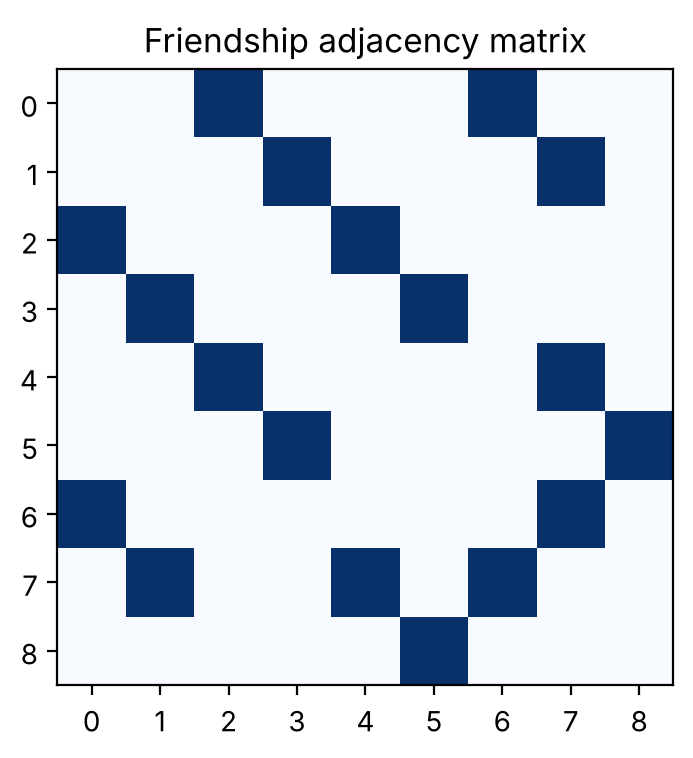

In [23]:
import matplotlib.pyplot as plt

friends = np.array([[0, 2], [0, 6], [1, 3], [1, 7], [2, 4],
                    [3, 5], [4, 7], [5, 8], [6, 7]])
n = friends.max() + 1
adj = np.zeros((n, n), dtype=int)
adj[friends[:, 0], friends[:, 1]] = 1
adj[friends[:, 1], friends[:, 0]] = 1      # friendship is symmetric

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(adj, cmap="Blues")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_title("Friendship adjacency matrix")
plt.show()

In [24]:
degree = adj.sum(axis=1)
print("friends per person:", degree)
print("most connected:", degree.argmax())
# (A @ A)[i, j] counts friends that i and j have in common
common = adj @ adj
print("common friends of 0 and 7:", common[0, 7])

friends per person: [2 2 2 2 2 2 2 3 1]
most connected: 7
common friends of 0 and 7: 1


When the edges are names, `np.unique(..., return_inverse=True)` converts them to integer ids:

In [25]:
edges = np.array([["Amy", "Frank"], ["Amy", "Katy"], ["Emma", "James"],
                  ["Cindy", "Rose"], ["Tim", "John"], ["Katy", "Rose"]])
names, ids = np.unique(edges, return_inverse=True)
ids = ids.reshape(edges.shape)
print(names)
print(ids)

['Amy' 'Cindy' 'Emma' 'Frank' 'James' 'John' 'Katy' 'Rose' 'Tim']
[[0 3]
 [0 6]
 [2 4]
 [1 7]
 [8 5]
 [6 7]]


Real networks are **sparse** (most entries are 0). For large graphs, store only the non-zero entries with `scipy.sparse`:

In [26]:
from scipy import sparse

m = len(names)
sp = sparse.coo_matrix((np.ones(len(ids)), (ids[:, 0], ids[:, 1])), shape=(m, m))
sp = sp + sp.T
print(sp.nnz, "non-zero entries out of", m * m)
sp.toarray()

12 non-zero entries out of 81


array([[0., 0., 0., 1., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 1., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0.]])

## 10. Random numbers the modern way

Create a **generator** with a seed, then draw from it. The seed makes results reproducible: everyone running the notebook gets the same numbers.

In [27]:
rng = np.random.default_rng(seed=42)
print(rng.integers(0, 10, size=(3, 3)))
print(rng.random(3))                         # uniform on [0, 1)
print(rng.normal(loc=70, scale=10, size=5))  # normal distribution
print(rng.choice(["A", "B", "C"], size=5, p=[0.5, 0.3, 0.2]))
arr = np.arange(10)
rng.shuffle(arr)
arr

[[0 7 6]
 [4 4 8]
 [0 6 2]]
[0.97562235 0.7611397  0.78606431]
[69.83198842 61.46956072 78.79397975 77.77791935 70.66030698]
['C' 'A' 'A' 'B' 'A']


array([6, 1, 2, 7, 3, 9, 8, 4, 0, 5])

> You may still see `np.random.rand(...)` and `np.random.seed(...)` in older code. They work, but the generator style above is the recommended one.

## Summary

- An `ndarray` holds one data type and has a `shape`.
- Prefer vectorised operations and broadcasting over loops.
- Slices are views; use `.copy()` when needed.
- Boolean masks filter data.
- `@` is matrix multiplication; `np.linalg` solves linear algebra problems.
- Use `np.random.default_rng(seed)` for reproducible random numbers.